# Boundary (move-on / decision) signal — figure generator

The boundary-signal intervention results are computed **live** in the clock notebooks (their cell outputs are the only persisted copy — there is no structured results file), so the values below are **hardcoded with their source of truth linked**, and re-dumped to `notebooks/Figures/boundary_signal/boundary_signal_values.json` for provenance.

Sources of truth (re-run these to recompute; the decision-head masks live at `results/multistep_clock/conditions/<model>/completion_mask/…/mask.pt` and the move-on vectors at `results/notebook_caches/02_diff_vs_boundary/`):
- **`notebooks/clock/11_goal_vs_impulse.ipynb` §4, cell 27** — goal-vs-decision dissociation (move-on argmax rate; α=2.0, N=256, pivot=−2). Also saves `results/dissociation/Qwen2.5-Coder-32B-Instruct/goal_vs_decision_moveon.png`.
- **`notebooks/clock/16_move_on_signal.ipynb` §1.1, cells 14–15** — move-on transfer across naming schemes (α=2.0, N=128/scheme).

Naming: the code calls these **decision/completion** heads; **boundary** is the paper-facing name.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
from rich import print as rich_print
GROUP='boundary_signal'; MODEL='Qwen2.5-Coder-32B-Instruct'
C_GOAL='#d1a054'; C_INTERV='firebrick'; C_NEUTRAL='#9a9a9a'

# ── SOURCE OF TRUTH: clock/11 §4 cell 27  (alpha=2.0, N=256, pivot=-2) ──
# printed output: 'move-on rate: clean=0.047  decision=0.977  goal=0.152'
DISSOC={'no intervention':0.047, 'goal heads\n(what)':0.152, 'boundary heads\n(when)':0.977}
DISSOC_META=dict(source='clock/11_goal_vs_impulse.ipynb §4 (cell 27)', alpha=2.0, n=256, pivot=-2,
                 metric='move-on argmax (full vocab)')

# ── SOURCE OF TRUTH: clock/16 §1.1 cells 14-15  (alpha=2.0, N=128/scheme) ──
# decision arm: kway=restricted 5-way, vocab=full-vocab (emitted target); clean = its own baseline
MOVEON={
 'a, b, c, \u2026':   dict(patched=dict(restricted=1.000, full=0.961), clean=dict(restricted=0.094, full=0.047)),
 'p, q, r, \u2026':   dict(patched=dict(restricted=0.992, full=0.977), clean=dict(restricted=0.070, full=0.055)),
 'var_1, var_2, \u2026': dict(patched=dict(restricted=1.000, full=1.000), clean=dict(restricted=0.070, full=0.070))}
MOVEON_META=dict(source='clock/16_move_on_signal.ipynb §1.1 (cells 14-15)', alpha=2.0, n_per_scheme=128,
                 note='one a,b,c move-on vector transferred to each scheme; decision arm')

os.makedirs(os.path.join(F.FIG_ROOT,GROUP),exist_ok=True)
json.dump(dict(model=MODEL, dissociation=dict(values=DISSOC,**DISSOC_META),
               move_on_transfer=dict(values=MOVEON,**MOVEON_META)),
          open(os.path.join(F.FIG_ROOT,GROUP,'boundary_signal_values.json'),'w'), indent=2)
print('wrote provenance json ->', os.path.join(F.FIG_ROOT,GROUP,'boundary_signal_values.json'))

wrote provenance json -> /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/boundary_signal/boundary_signal_values.json


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/boundary_signal/goal_vs_boundary_moveon.pdf


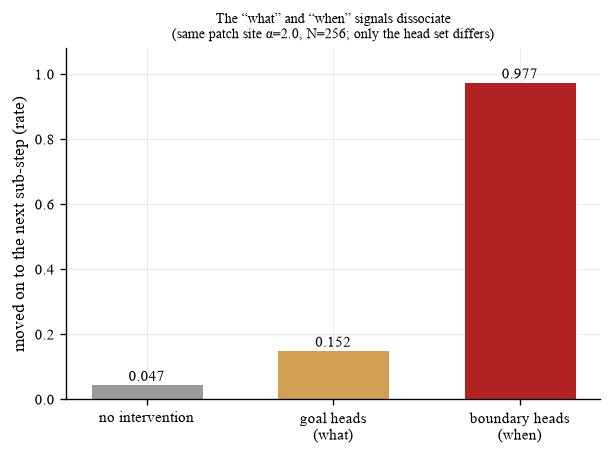

In [2]:
# ── Figure: the two signals are separable (goal vs boundary/decision heads, same patch) ──
names=list(DISSOC); vals=[DISSOC[k] for k in names]; cols=[C_NEUTRAL,C_GOAL,C_INTERV]
fig,ax=plt.subplots(figsize=(5.2,3.9))
bars=ax.bar(np.arange(len(names)), vals, 0.6, color=cols, edgecolor='white', linewidth=0.6)
for r in bars: ax.annotate(f'{r.get_height():.3f}',(r.get_x()+r.get_width()/2,r.get_height()),
                           ha='center',va='bottom',fontsize=9)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names)
ax.set_ylabel('moved on to the next sub-step (rate)'); ax.set_ylim(0,1.08)
ax.set_title(f'The \u201cwhat\u201d and \u201cwhen\u201d signals dissociate\n'
             f'(same patch site \u03b1={DISSOC_META["alpha"]}, N={DISSOC_META["n"]}; only the head set differs)',fontsize=8.5)
fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,'goal_vs_boundary_moveon')); plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/boundary_signal/move_on_transfer.pdf


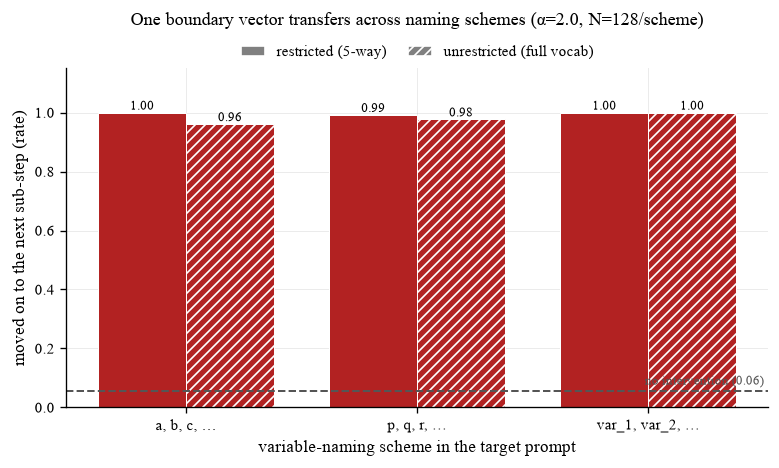

In [3]:
# ── Figure: one boundary vector moves the LM on, across variable-naming schemes ──
schemes=list(MOVEON); x=np.arange(len(schemes)); w=0.38
restr=[MOVEON[s]['patched']['restricted'] for s in schemes]
full =[MOVEON[s]['patched']['full'] for s in schemes]
clean_full=float(np.mean([MOVEON[s]['clean']['full'] for s in schemes]))
fig,ax=plt.subplots(figsize=(6.6,4.0))
ax.bar(x-w/2, restr, w, **F.metric_kw('faithfulness', C_INTERV))          # solid = restricted 5-way
ax.bar(x+w/2, full,  w, **F.metric_kw('causality',    C_INTERV))          # white-striped = full vocab
for xi in range(len(schemes)):
    ax.annotate(f'{restr[xi]:.2f}',(xi-w/2,restr[xi]),ha='center',va='bottom',fontsize=8)
    ax.annotate(f'{full[xi]:.2f}',(xi+w/2,full[xi]),ha='center',va='bottom',fontsize=8)
ax.axhline(clean_full, ls='--', lw=1.2, color='#555', zorder=1)
ax.annotate(f'no intervention ({clean_full:.2f})',(len(schemes)-0.5,clean_full+0.02),ha='right',fontsize=7.5,color='#555')
ax.set_xticks(x); ax.set_xticklabels(schemes)
ax.set_xlabel('variable-naming scheme in the target prompt')
ax.set_ylabel('moved on to the next sub-step (rate)'); ax.set_ylim(0,1.15)
ax.set_title(f'One boundary vector transfers across naming schemes (\u03b1={MOVEON_META["alpha"]}, N={MOVEON_META["n_per_scheme"]}/scheme)',fontsize=8.5)
_h=F.metric_legend_handles(labels=('restricted (5-way)','unrestricted (full vocab)'))
F.legend_top(ax, handles=_h, labels=[h.get_label() for h in _h])
fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,'move_on_transfer')); plt.show()